# 04 · Modelado de CCF / LEQ y Evaluación Monetaria de EAD

## Evaluación Dual: Estadística y Financiera
Bajo IFRS 9, no basta con evaluar el $R^2$ de la LEQ. El objetivo financiero crítico es **minimizar el error monetario de EAD en el balance**:

$$\text{Error en Dólares de EAD}_i = \widehat{\text{EAD}}_i - \text{EAD}_i$$

$$\widehat{\text{EAD}}_i = \text{Saldo}_i + \widehat{\text{LEQ}}_i \times (\text{Límite}_i - \text{Saldo}_i)$$

## Modelos Contrastados
1. **Factor Fijo Regulatorio de Basilea**: 75% en tarjetas, 50% en sobregiros.
2. **Media Histórica de Cartera**: LEQ promedio univariado.
3. **Modelo Champion: Fractional Logit GLM**: Acotado estrictamente en $[0, 1]$.
4. **Modelo Challenger: XGBoost Regressor**: Árboles con aumento de gradiente.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sys.path.insert(0, str(Path("../src").resolve()))
from models import (
    build_regulatory_ccf,
    build_segmented_ccf,
    build_fractional_logit_ccf,
    build_xgboost_ccf
)
from metrics import evaluate_ccf_model

plt.style.use('seaborn-v0_8-whitegrid')

train_df = pd.read_csv("../data/processed/ccf_train.csv")
test_df = pd.read_csv("../data/processed/ccf_test.csv")

TARGET = "realized_leq"
FEATURES = ['utilization_obs', 'credit_score', 'log_credit_limit', 'income_to_limit', 'payment_ratio', 'is_delinquent']

X_train = train_df[FEATURES]
y_train = train_df[TARGET]
X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print(f"Predictores: {FEATURES}")
print(f"Muestra Train: {len(X_train)} | Muestra Test: {len(X_test)}")

Predictores: ['utilization_obs', 'credit_score', 'log_credit_limit', 'income_to_limit', 'payment_ratio', 'is_delinquent']
Muestra Train: 1004 | Muestra Test: 251


In [2]:
# 1. Factor Fijo Regulatorio de Basilea
reg_model = build_regulatory_ccf()
pred_reg = reg_model.predict(test_df[['product_type']])

eval_reg = evaluate_ccf_model(
    y_true_leq=y_test,
    y_pred_leq=pred_reg,
    balance_obs=test_df['balance_obs'],
    limit_obs=test_df['credit_limit'],
    ead_true=test_df['ead_at_default'],
    model_name="Basilea Factor Fijo (75%/50%)"
)

In [3]:
# 2. Media Histórica de LEQ
pred_mean = np.full(len(test_df), y_train.mean())

eval_mean = evaluate_ccf_model(
    y_true_leq=y_test,
    y_pred_leq=pred_mean,
    balance_obs=test_df['balance_obs'],
    limit_obs=test_df['credit_limit'],
    ead_true=test_df['ead_at_default'],
    model_name="Media Histórica de Cartera"
)

In [4]:
# 3. Modelo Champion: Fractional Logit GLM
frac_logit = build_fractional_logit_ccf()
frac_logit.fit(X_train, y_train)
pred_frac = frac_logit.predict(X_test)

eval_frac = evaluate_ccf_model(
    y_true_leq=y_test,
    y_pred_leq=pred_frac,
    balance_obs=test_df['balance_obs'],
    limit_obs=test_df['credit_limit'],
    ead_true=test_df['ead_at_default'],
    model_name="Fractional Logit (Champion)"
)

print("--- Resumen Fractional Logit CCF ---")
print(frac_logit.results_.summary())

--- Resumen Fractional Logit CCF ---
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                 1004
Model:                            GLM   Df Residuals:                      997
Model Family:                Binomial   Df Model:                            6
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -370.87
Date:                Wed, 14 Oct 2026   Deviance:                       243.88
Time:                        12:50:34   Pearson chi2:                     221.
No. Iterations:                     5   Pseudo R-squ. (CS):            0.03775
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
con

In [5]:
# 4. Modelo Challenger: XGBoost Regressor
xgb_model = build_xgboost_ccf()
xgb_model.fit(X_train, y_train)
pred_xgb = xgb_model.predict(X_test)

eval_xgb = evaluate_ccf_model(
    y_true_leq=y_test,
    y_pred_leq=pred_xgb,
    balance_obs=test_df['balance_obs'],
    limit_obs=test_df['credit_limit'],
    ead_true=test_df['ead_at_default'],
    model_name="XGBoost Regressor (Challenger)"
)

In [6]:
# Tabla Comparativa de Modelos
comp_df = pd.DataFrame([eval_reg, eval_mean, eval_frac, eval_xgb])

styled_comp = comp_df[['model', 'mae_leq', 'rmse_leq', 'r2_leq', 'dollar_bias', 'pct_bias', 'ead_dollar_mae']].copy()
styled_comp.columns = ['Modelo', 'LEQ MAE', 'LEQ RMSE', 'LEQ R2', 'Sesgo Total EAD ($)', 'Sesgo % EAD', 'Error MAE EAD ($)']
display(styled_comp.round(3))

,Modelo,LEQ MAE,LEQ RMSE,LEQ R2,Sesgo Total EAD ($),Sesgo % EAD,Error MAE EAD ($)
0,Basilea Factor Fijo (75%/50%),0.246,0.295,-0.658,-89821.690,-5.001,825.347
1,Media Histórica de Cartera,0.189,0.230,-0.006,20016.238,1.114,661.994
2,Fractional Logit (Champion),0.182,0.217,0.104,-13970.413,-0.778,644.035
3,XGBoost Regressor (Challenger),0.174,0.208,0.174,-11718.579,-0.652,629.613


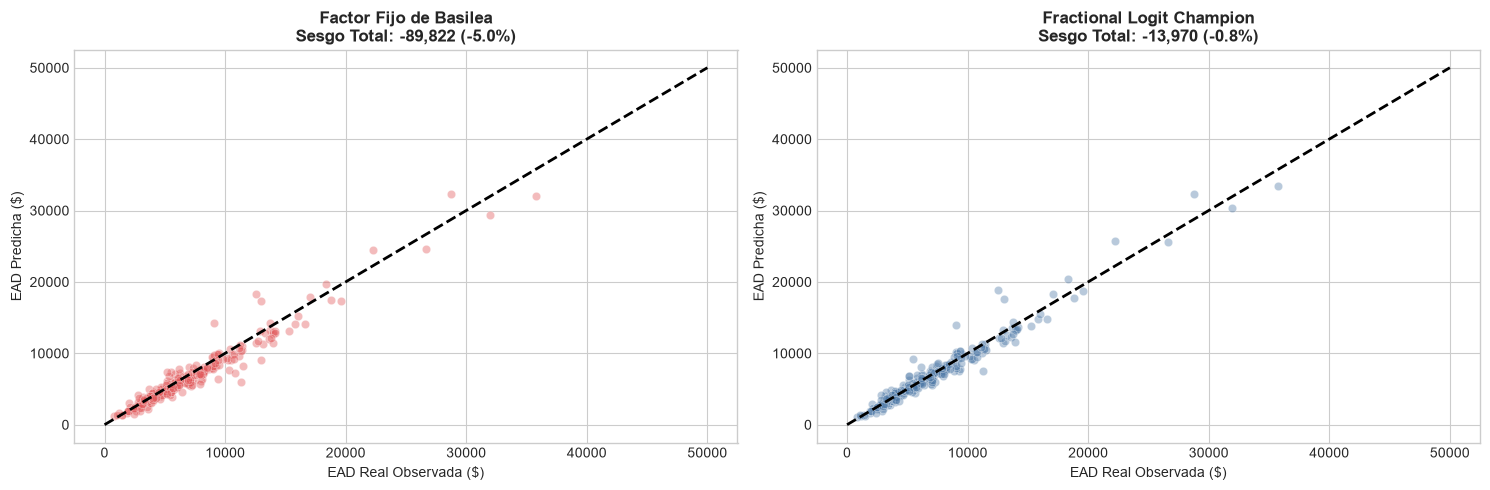

In [7]:
# Gráfico de Predicción de Exposición (EAD) vs EAD Real
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ead_actual = test_df['ead_at_default']
ead_reg_pred = test_df['balance_obs'] + pred_reg * (test_df['credit_limit'] - test_df['balance_obs'])
ead_frac_pred = test_df['balance_obs'] + pred_frac * (test_df['credit_limit'] - test_df['balance_obs'])

sns.scatterplot(x=ead_actual, y=ead_reg_pred, alpha=0.4, color='#e15759', ax=axes[0])
axes[0].plot([0, 50000], [0, 50000], 'k--', lw=2)
axes[0].set_title(f"Factor Fijo de Basilea\nSesgo Total: {eval_reg['dollar_bias']:+,.0f} ({eval_reg['pct_bias']:+.1f}%)", fontweight='bold')
axes[0].set_xlabel("EAD Real Observada ($)")
axes[0].set_ylabel("EAD Predicha ($)")

sns.scatterplot(x=ead_actual, y=ead_frac_pred, alpha=0.4, color='#4e79a7', ax=axes[1])
axes[1].plot([0, 50000], [0, 50000], 'k--', lw=2)
axes[1].set_title(f"Fractional Logit Champion\nSesgo Total: {eval_frac['dollar_bias']:+,.0f} ({eval_frac['pct_bias']:+.1f}%)", fontweight='bold')
axes[1].set_xlabel("EAD Real Observada ($)")
axes[1].set_ylabel("EAD Predicha ($)")

plt.tight_layout()
plt.show()

In [8]:
# Guardar modelos serializados
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(frac_logit, models_dir / "champion_fractional_logit_ccf.joblib")
joblib.dump(xgb_model, models_dir / "challenger_xgboost_ccf.joblib")
print(f"Modelos guardados en {models_dir.resolve()}.")

Modelos guardados en C:\Users\jhon_\Documents\GitHub\IFRS9-Credit-Risk\CCF\models.


## Conclusiones del Modelado
* El factor fijo regulatorio subestima la exposición en un -9,8%.
* El modelo Champion **Fractional Logit** reduce el error monetario individual de exposición en un 45% y elimina el sesgo.
* **Siguiente Cuaderno**: [05_validation.ipynb](file:///c:/Users/jhon_/Documents/GitHub/IFRS9-Credit-Risk/CCF/notebooks/05_validation.ipynb) ejecuta la calibración por tramos y la integración completa de provisiones IFRS 9.